# 01 · Exploración y preparación de los datos (Módulo 1)
**Sistema de apoyo para detección de tumores cerebrales en resonancia magnética**

Problema: clasificación binaria, **tumor** (glioma + meningioma + pituitary) contra **sin tumor** (notumor).

Este notebook:
1. Hace el inventario del dataset con Pandas (8 carpetas: Training y Testing, 4 clases).
2. Revisa tamaños y limpia lo que no se puede leer.
3. Limpia el dataset juntando las 8 carpetas: quita los **aumentos sintéticos** que ya traía (archivos `aug`), las **copias** (exactas, recomprimidas, en espejo o giradas) y los pares con etiquetas contradictorias. Después forma **grupos de similitud** para que las imágenes muy parecidas nunca queden repartidas entre entrenamiento y prueba.
4. Describe el brillo y el contraste por clase, con un intervalo de confianza y pruebas de hipótesis.
5. Divide en entrenamiento (≈80 %) y prueba (≈20 %) **por grupos de similitud**, estratificado por las 4 clases, con semilla 42, y fija los 5 pliegues de la validación cruzada, también por grupos.
6. Guarda `datos/manifiesto.csv` y `datos/duplicados.csv`.

Es un proyecto académico de apoyo a la decisión. No es un dispositivo médico.

In [1]:
import sys
import time
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend" / "ml").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import hashlib
import warnings
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image
from scipy import stats
from sklearn.model_selection import train_test_split

from app.backend.ml import config
from app.backend.ml.duplicados import UMBRAL_CORRELACION, agrupar, maxima_correlacion, miniatura, tabla_pares
from app.backend.ml.entrenar import apartar_validacion, pliegues_estratificados
from app.backend.ml.metricas import wilson
from app.backend.ml.preprocesar import leer_imagen, preparar
from app.backend.ml.rasgos import rasgos_basicos
from app.backend.ml.red import pesos_clase

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
config.fijar_semillas()
FIGURAS = config.RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
INICIO = time.time()
print("Raíz del proyecto:", config.RAIZ)
print("Versiones:", config.versiones())

Raíz del proyecto: C:\proyectos\tumores-cerebrales
Versiones: {'python': '3.12.10', 'numpy': '2.5.5', 'sklearn': '1.9.1', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'opencv': '5.1.0', 'pandas': '3.1.1'}


## 1. Inventario
Se listan todos los archivos de las 8 carpetas. La división original Training/Testing del dataset **no se usa** para evaluar: más abajo se juntan todas las imágenes, se quitan las repetidas y se vuelve a dividir.

In [2]:
filas, otros_archivos = [], []
for carpeta in ["Training", "Testing"]:
    for clase in config.CLASES:
        d = config.DATOS / carpeta / clase
        if not d.is_dir():
            raise FileNotFoundError(f"No existe la carpeta {d}")
        for f in sorted(d.iterdir()):
            if f.suffix.lower() in config.EXTENSIONES:
                filas.append({"ruta": f.relative_to(config.RAIZ).as_posix(), "carpeta_origen": carpeta,
                              "clase": clase, "extension": f.suffix.lower(), "bytes": f.stat().st_size})
            else:
                otros_archivos.append(str(f))
df = pd.DataFrame(filas)
df["es_tumor"] = (df.clase != "notumor").astype(int)
print(f"Imágenes encontradas: {len(df):,} · archivos que no son imagen: {len(otros_archivos)}")
inventario = pd.crosstab(df.carpeta_origen, df.clase, margins=True, margins_name="total")
display(inventario)
print("Extensiones:", df.extension.value_counts().to_dict())

Imágenes encontradas: 7,200 · archivos que no son imagen: 0


clase,glioma,meningioma,notumor,pituitary,total
carpeta_origen,,,,,
Testing,400,400,400,400,1600
Training,1400,1400,1400,1400,5600
total,1800,1800,1800,1800,7200


Extensiones: {'.jpg': 7200}


## 2. Lectura, tamaños y huellas
Cada imagen se lee **una sola vez** con `np.fromfile` + `cv2.imdecode` (funciona con acentos en Windows) y se calcula:
- ancho y alto originales;
- **SHA-256 de los pixeles decodificados** (detecta copias exactas aunque el archivo tenga otro nombre);
- **hash perceptual**: la imagen se reduce a 16 × 16 en grises y cada pixel se compara con el promedio (256 bits). Detecta copias con cambios mínimos de compresión o tamaño;
- las **mismas dos huellas sobre la imagen ya preparada** (recorte del cerebro y 160 × 160). Sirven para atrapar copias que solo difieren en el marco negro o en el tamaño del archivo: los pixeles originales son distintos, pero lo que ve el modelo es idéntico;
- una **miniatura de 64 × 64 en grises** de la imagen original y otra de la preparada, para buscar copias en espejo, giradas o recomprimidas (sección 3);
- brillo y contraste de la imagen ya preparada, que es lo que verá el modelo.

In [3]:
def hash_perceptual(img, n=16, codigo=cv2.COLOR_BGR2GRAY):
    """Hash promedio de 16x16 (como el script de referencia): 256 bits en hexadecimal."""
    gris = cv2.cvtColor(img, codigo)
    g = np.asarray(Image.fromarray(gris).resize((n, n), Image.Resampling.BILINEAR), dtype=np.float32)
    bits = (g > g.mean()).flatten()
    return np.packbits(bits).tobytes().hex()


def analizar(ruta_rel):
    try:
        img = leer_imagen(config.RAIZ / ruta_rel)
    except ValueError:
        return {"legible": False}
    sha = hashlib.sha256(str(img.shape).encode() + img.tobytes()).hexdigest()
    lista = preparar(img)
    basicos = rasgos_basicos(lista)
    en_grises = bool((img[..., 0] == img[..., 1]).all() and (img[..., 1] == img[..., 2]).all())
    return {"legible": True, "alto": img.shape[0], "ancho": img.shape[1], "en_grises": en_grises,
            "sha256": sha, "hash_perceptual": hash_perceptual(img),
            "sha256_preparada": hashlib.sha256(lista.tobytes()).hexdigest(),
            "hash_perceptual_preparada": hash_perceptual(lista, codigo=cv2.COLOR_RGB2GRAY),
            "mini_original": miniatura(img), "mini_preparada": miniatura(lista),
            "brillo": float(basicos[0]), "contraste": float(basicos[1])}


t0 = time.time()
with ThreadPoolExecutor(max_workers=12) as ex:
    info = list(ex.map(analizar, df.ruta))
df = pd.concat([df, pd.DataFrame(info)], axis=1)
print(f"Imágenes analizadas en {time.time() - t0:.0f} s")

Imágenes analizadas en 33 s


### 2.1 Limpieza
Se quitan los archivos que no se pueden leer y las imágenes demasiado pequeñas (menos de 32 pixeles por lado).

Ilegibles quitadas: 0 · demasiado pequeñas quitadas: 0 · quedan 7,200
Imágenes guardadas en grises (3 canales iguales): 7,071 de 7,200
Tamaños distintos: 447 · el más común: (np.int64(512), np.int64(512)) con 5,014 imágenes


,ancho,alto,bytes
count,7200.0,7200.0,7200.0
mean,453.3,456.9,23312.4
std,130.0,124.4,16301.0
min,150.0,167.0,3681.0
25%,442.0,449.0,16113.5
50%,512.0,512.0,21705.5
75%,512.0,512.0,27392.2
max,1375.0,1446.0,306492.0


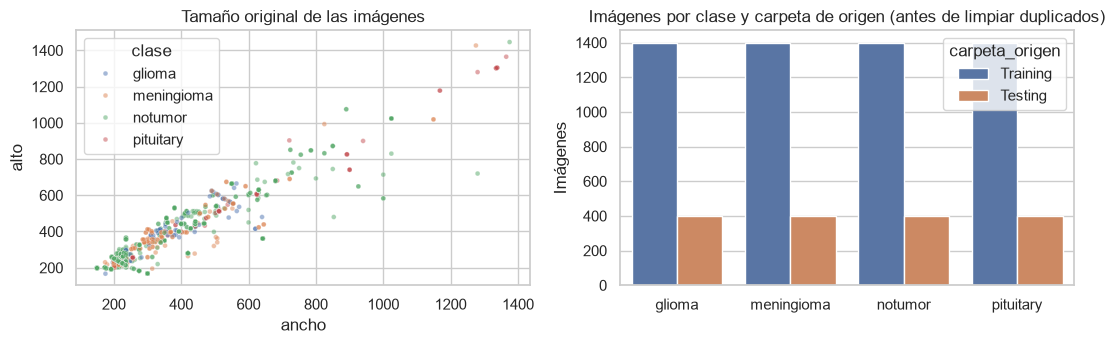

In [4]:
n_ilegibles = int((~df.legible).sum())
df = df[df.legible].drop(columns="legible").reset_index(drop=True)
muy_chicas = (df.ancho < 32) | (df.alto < 32)
n_chicas = int(muy_chicas.sum())
df = df[~muy_chicas].reset_index(drop=True)
df[["alto", "ancho"]] = df[["alto", "ancho"]].astype(int)
MINI_O = np.stack(df.pop("mini_original").to_list())    # miniaturas de la imagen original
MINI_P = np.stack(df.pop("mini_preparada").to_list())   # miniaturas de la imagen preparada (recortada)
print(f"Ilegibles quitadas: {n_ilegibles} · demasiado pequeñas quitadas: {n_chicas} · quedan {len(df):,}")
print(f"Imágenes guardadas en grises (3 canales iguales): {int(df.en_grises.sum()):,} de {len(df):,}")

tamanos = df.groupby(["ancho", "alto"]).size().sort_values(ascending=False)
print(f"Tamaños distintos: {len(tamanos)} · el más común: {tamanos.index[0]} con {tamanos.iloc[0]:,} imágenes")
display(df[["ancho", "alto", "bytes"]].describe().round(1))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
sns.scatterplot(data=df, x="ancho", y="alto", hue="clase", hue_order=config.CLASES, s=12, alpha=0.5, ax=axs[0])
axs[0].set_title("Tamaño original de las imágenes")
sns.countplot(data=df, x="clase", hue="carpeta_origen", order=config.CLASES, ax=axs[1])
axs[1].set_title("Imágenes por clase y carpeta de origen (antes de limpiar duplicados)")
axs[1].set_xlabel(""); axs[1].set_ylabel("Imágenes")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_01_inventario.png", dpi=130); plt.show()

## 3. Limpieza: aumentos, copias y etiquetas contradictorias
Si la misma toma está en entrenamiento y en prueba, el modelo "ya vio el examen" y las métricas salen infladas. Este dataset trae mucha repetición, de varios tipos. Se trata en tres pasos:

**Paso 1 · Aumentos sintéticos del dataset.** Los archivos con `aug` en el nombre son imágenes giradas o con zoom que alguien generó a partir de otras del mismo dataset. No son tomas reales: se quitan **todos**.

**Paso 2 · Copias.** Dos imágenes son la misma toma si la **correlación entre sus miniaturas de 64 × 64 es mayor de 0.98**, comparando una con la otra tal cual y en las otras 7 orientaciones (espejo horizontal, espejo vertical, giro de 180°, giros de 90° y 270° y las dos transpuestas), sobre la imagen original y sobre la preparada. Esto incluye las copias exactas (mismo SHA-256), las recomprimidas en JPEG y las volteadas, que las huellas no detectan.
- **Se elimina por pares, sin encadenar:** se recorren las imágenes en orden y una imagen se elimina **solo si** tiene correlación mayor de 0.98 con una imagen que **se conserva**. (Encadenar "A se parece a B, B a C, C a D…" llegaba a juntar decenas de tomas distintas y a borrar imágenes legítimas.)
- **El hash perceptual de 16 × 16 ya no elimina por sí solo:** resume la silueta y juntaba imágenes distintas. Ahora solo sirve, más abajo, para mantener del mismo lado a las imágenes que lo comparten.
- **Etiquetas contradictorias:** si dos imágenes con correlación mayor de 0.98 tienen **clases distintas** (tumor contra sin tumor, o dos tipos de tumor), se descartan **las dos**, porque no se sabe cuál etiqueta es la correcta.

**Paso 3 · Grupos de similitud (sección 3.2).** Las imágenes que quedan y se parecen mucho (correlación mayor de 0.95) **no se borran**: se agrupan, y la división se hace por grupos.

In [5]:
HUELLAS = ["sha256", "hash_perceptual", "sha256_preparada", "hash_perceptual_preparada"]
UMBRAL_GRUPO = 0.95       # similitud para formar grupos (sección 3.2)
MARGEN = 1e-4             # margen numérico: los pares se buscan un poco por debajo del umbral
t0 = time.time()
tabla = pd.concat([pd.DataFrame(tabla_pares(MINI_O, UMBRAL_GRUPO - MARGEN)).assign(miniatura="original"),
                   pd.DataFrame(tabla_pares(MINI_P, UMBRAL_GRUPO - MARGEN)).assign(miniatura="preparada")], ignore_index=True)
# un renglón por par: la mayor correlación entre la miniatura original y la preparada
tabla = tabla.sort_values("correlacion", ascending=False, kind="stable").drop_duplicates(["i", "j"]).reset_index(drop=True)
print(f"Comparación de miniaturas (todas contra todas, 8 orientaciones) en {time.time() - t0:.0f} s · "
      f"pares con correlación > {UMBRAL_GRUPO}: {len(tabla):,} · > {UMBRAL_CORRELACION}: {int((tabla.correlacion > UMBRAL_CORRELACION).sum()):,}")

# Paso 1: aumentos sintéticos
df["es_aug"] = df.ruta.map(lambda r: "aug" in Path(r).name.lower())
print(f"Archivos 'aug' (aumentos del dataset): {int(df.es_aug.sum())} ·", df[df.es_aug].groupby(["carpeta_origen", "clase"]).size().to_dict())


# Paso 2: copias por pares (sin encadenar) y etiquetas contradictorias
es_aug = df.es_aug.to_numpy()
clases, shas = df.clase.to_numpy(), df.sha256.to_numpy()
fuertes = tabla[(tabla.correlacion > UMBRAL_CORRELACION) & ~es_aug[tabla.i] & ~es_aug[tabla.j]].reset_index(drop=True)
choque = fuertes[clases[fuertes.i] != clases[fuertes.j]]
contradictoria = np.zeros(len(df), dtype=bool)
contradictoria[choque.i] = True
contradictoria[choque.j] = True

def correlacion_directa(i, j, mini):
    a, b = mini[i].ravel() - mini[i].mean(), mini[j].ravel() - mini[j].mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


vecinos = {}
for i, j, v, c in zip(fuertes.i, fuertes.j, fuertes.variante, fuertes.correlacion):
    vecinos.setdefault(int(i), []).append((int(j), v, float(c)))
    vecinos.setdefault(int(j), []).append((int(i), v, float(c)))

CAUSA_AUG, CAUSA_CONTRA = "aumento_del_dataset", "etiqueta_contradictoria"
CAUSA_EXACTA, CAUSA_CASI, CAUSA_ESPEJO = "copia_exacta", "casi_identica", "espejo_o_giro"
accion = np.array(["conservada"] * len(df), dtype=object)
causa = np.array([""] * len(df), dtype=object)
referencia = np.full(len(df), -1)
ref_variante = np.array([""] * len(df), dtype=object)
ref_correlacion = np.full(len(df), np.nan)
for i in range(len(df)):                      # orden: Training antes que Testing, por clase y nombre
    if es_aug[i]:
        accion[i], causa[i] = "quitada", CAUSA_AUG
        continue
    if contradictoria[i]:
        accion[i], causa[i] = "quitada", CAUSA_CONTRA
        otros = [(j, v, c) for j, v, c in vecinos.get(i, []) if clases[j] != clases[i]]
        referencia[i], ref_variante[i], ref_correlacion[i] = max(otros, key=lambda x: x[2])
        continue
    conservadas = [(j, v, c) for j, v, c in vecinos.get(i, []) if j < i and accion[j] == "conservada"]
    if conservadas:
        exactas = [x for x in conservadas if shas[x[0]] == shas[i]]
        j, v, c = exactas[0] if exactas else max(conservadas, key=lambda x: x[2])
        accion[i] = "quitada"
        # "casi idéntica" si ya se parecen sin voltear; "espejo o giro" solo si hace falta voltear para verlo
        sin_voltear = max(correlacion_directa(i, j, MINI_O), correlacion_directa(i, j, MINI_P)) > UMBRAL_CORRELACION
        causa[i] = CAUSA_EXACTA if exactas else (CAUSA_CASI if (v == "directa" or sin_voltear) else CAUSA_ESPEJO)
        referencia[i], ref_variante[i], ref_correlacion[i] = j, v, c
df["accion"], df["causa"] = accion, causa

por_causa = pd.crosstab(df.causa.replace("", "SE CONSERVA"), df.clase, margins=True, margins_name="total")
por_causa = por_causa.reindex([CAUSA_AUG, CAUSA_CONTRA, CAUSA_EXACTA, CAUSA_CASI, CAUSA_ESPEJO, "SE CONSERVA", "total"]).fillna(0).astype(int)
print("Imágenes por causa de eliminación y clase:")
display(por_causa)
quitadas = df[df.accion == "quitada"]
cruzan = (quitadas.causa.isin([CAUSA_EXACTA, CAUSA_CASI, CAUSA_ESPEJO]).to_numpy()
          & (quitadas.carpeta_origen.to_numpy() != df.carpeta_origen.to_numpy()[np.maximum(referencia[quitadas.index], 0)]))
print(f"Copias eliminadas cuya pareja conservada estaba en la otra carpeta (Training / Testing): {int(cruzan.sum())}")
print(f"Pares con etiquetas contradictorias: {len(choque)} ({int(contradictoria.sum())} imágenes). Clases que chocan:",
      pd.Series([" + ".join(sorted((a, b))) for a, b in zip(clases[choque.i], clases[choque.j])]).value_counts().to_dict())

# Comparación con el método anterior (encadenamiento transitivo + hash perceptual por sí solo), sobre las mismas imágenes sin 'aug'
sin_aug = np.flatnonzero(~es_aug)
pos = -np.ones(len(df), dtype=int); pos[sin_aug] = np.arange(len(sin_aug))
enlaces = [(pos[i], pos[j]) for i, j in zip(fuertes.i, fuertes.j)]
sub = df.iloc[sin_aug].reset_index(drop=True)
for columna in HUELLAS:
    for _, indices in sub.groupby(columna).indices.items():
        enlaces += [(int(indices[0]), int(k)) for k in indices[1:]]
sub["grupo_encadenado"] = agrupar(len(sub), enlaces)
sub = sub[sub.groupby("grupo_encadenado").clase.transform("nunique") == 1].drop_duplicates("grupo_encadenado")
recuperadas = pd.DataFrame({"metodo_anterior_encadenado": sub.clase.value_counts(),
                            "metodo_actual_por_pares": df[df.accion == "conservada"].clase.value_counts()}).reindex(config.CLASES).fillna(0).astype(int)
recuperadas["recuperadas"] = recuperadas.metodo_actual_por_pares - recuperadas.metodo_anterior_encadenado
recuperadas.loc["total"] = recuperadas.sum()
print("Imágenes conservadas por clase: método anterior contra método actual (ambos sin los archivos 'aug'):")
display(recuperadas)

df["ruta_referencia"] = [df.ruta[j] if j >= 0 else "" for j in referencia]
df["clase_referencia"] = [df.clase[j] if j >= 0 else "" for j in referencia]
df["variante"], df["correlacion"] = ref_variante, ref_correlacion
columnas_dup = ["ruta", "carpeta_origen", "clase", "es_tumor", "sha256", "hash_perceptual", "accion", "causa",
                "ruta_referencia", "clase_referencia", "variante", "correlacion"]
df[df.accion == "quitada"][columnas_dup].to_csv(config.DUPLICADOS, index=False, encoding="utf-8")
print("Guardado:", config.DUPLICADOS, f"({int((df.accion == 'quitada').sum()):,} imágenes eliminadas, con su causa y la imagen conservada a la que se parecen)")
tabla.assign(ruta_a=df.ruta.to_numpy()[tabla.i], ruta_b=df.ruta.to_numpy()[tabla.j], clase_a=clases[tabla.i], clase_b=clases[tabla.j])[
    ["ruta_a", "clase_a", "ruta_b", "clase_b", "variante", "miniatura", "correlacion"]].to_csv(config.DATOS / "pares_casi_duplicados.csv", index=False, encoding="utf-8")
print("Guardado:", config.DATOS / "pares_casi_duplicados.csv", f"({len(tabla):,} pares con correlación > {UMBRAL_GRUPO})")

Comparación de miniaturas (todas contra todas, 8 orientaciones) en 70 s · pares con correlación > 0.95: 24,591 · > 0.98: 18,025
Archivos 'aug' (aumentos del dataset): 203 · {('Testing', 'meningioma'): 103, ('Training', 'meningioma'): 100}


Imágenes por causa de eliminación y clase:


clase,glioma,meningioma,notumor,pituitary,total
causa,,,,,
aumento_del_dataset,0,203,0,0,203
etiqueta_contradictoria,5,16,0,13,34
copia_exacta,12,89,86,28,215
casi_identica,5,35,361,8,409
espejo_o_giro,321,638,986,794,2739
SE CONSERVA,1457,819,367,957,3600
total,1800,1800,1800,1800,7200


Copias eliminadas cuya pareja conservada estaba en la otra carpeta (Training / Testing): 1078
Pares con etiquetas contradictorias: 27 (34 imágenes). Clases que chocan: {'glioma + meningioma': 14, 'meningioma + pituitary': 13}
Imágenes conservadas por clase: método anterior contra método actual (ambos sin los archivos 'aug'):


,metodo_anterior_encadenado,metodo_actual_por_pares,recuperadas
clase,,,
glioma,1419,1457,38
meningioma,807,819,12
notumor,340,367,27
pituitary,944,957,13
total,3510,3600,90


Guardado: C:\proyectos\tumores-cerebrales\datos\duplicados.csv (3,600 imágenes eliminadas, con su causa y la imagen conservada a la que se parecen)
Guardado: C:\proyectos\tumores-cerebrales\datos\pares_casi_duplicados.csv (24,591 pares con correlación > 0.95)


### Ejemplos de pares en espejo
Cada fila es un par que las huellas **no** detectan: a la izquierda una imagen, en medio su pareja tal como está en el dataset y a la derecha la pareja volteada, que coincide con la primera. Se eligen pares cuya correlación sin voltear es baja (imágenes poco simétricas), para que el espejo se note a simple vista.

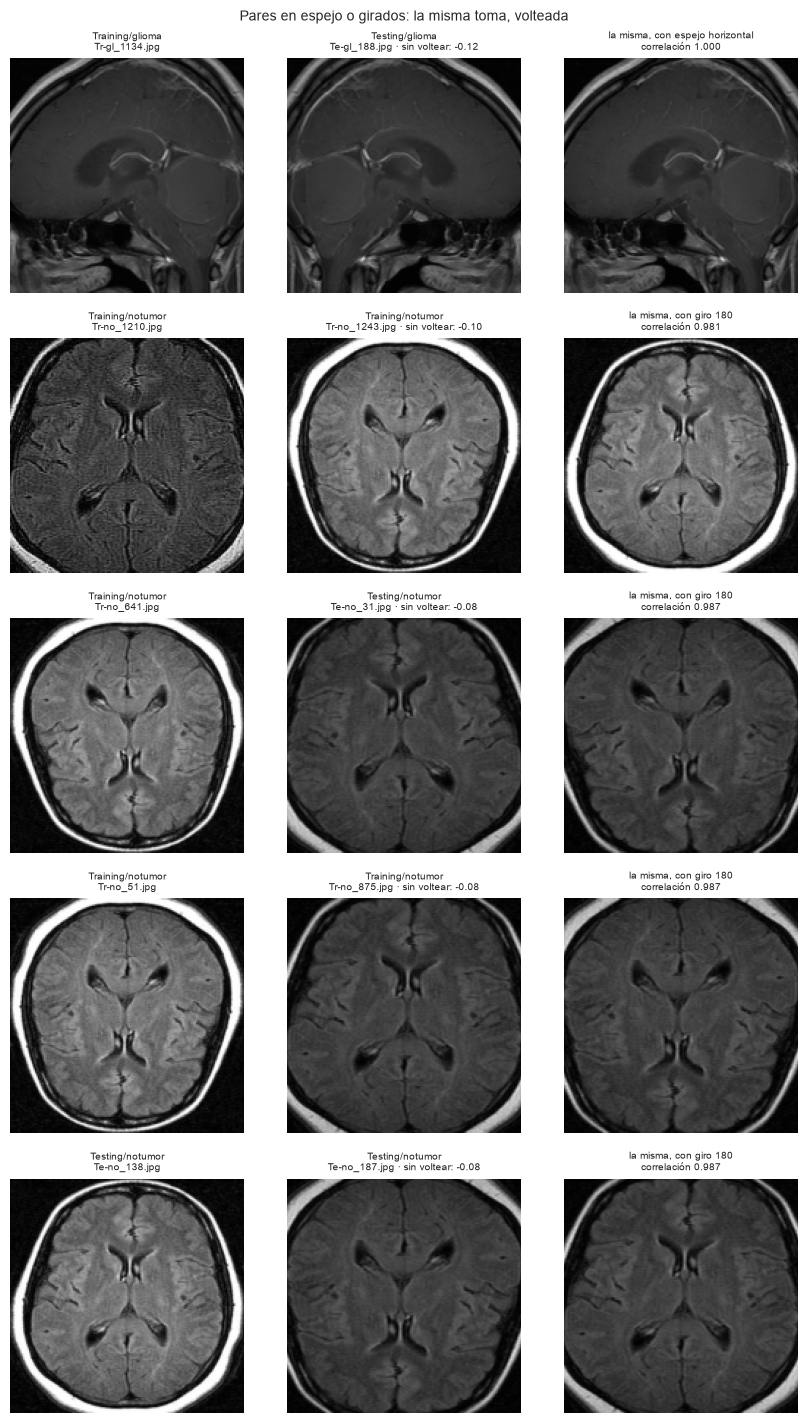

In [6]:
VOLTEAR = {"directa": lambda a: a, "espejo_horizontal": lambda a: a[:, ::-1], "espejo_vertical": lambda a: a[::-1], "giro_180": lambda a: a[::-1, ::-1],
           "giro_90": lambda a: np.rot90(a, 1), "giro_270": lambda a: np.rot90(a, 3),
           "transpuesta": lambda a: a.transpose(1, 0, 2), "antitranspuesta": lambda a: a[::-1, ::-1].transpose(1, 0, 2)}
candidatos = fuertes[fuertes.variante != "directa"].copy()
if len(candidatos):
    candidatos["directa"] = [correlacion_directa(i, j, MINI_P) for i, j in zip(candidatos.i, candidatos.j)]
    muestra = candidatos.sort_values("directa").drop_duplicates("i").drop_duplicates("j")
    muestra = muestra[~muestra.j.isin(muestra.i)].head(5)
    fig, axs = plt.subplots(len(muestra), 3, figsize=(8.5, 2.9 * len(muestra)), squeeze=False)
    for fila, r in zip(axs, muestra.itertuples()):
        a = preparar(leer_imagen(config.RAIZ / df.ruta[r.i])); b = preparar(leer_imagen(config.RAIZ / df.ruta[r.j]))
        fila[0].imshow(a); fila[0].set_title(f"{df.carpeta_origen[r.i]}/{df.clase[r.i]}\n{Path(df.ruta[r.i]).name}", fontsize=7)
        fila[1].imshow(b); fila[1].set_title(f"{df.carpeta_origen[r.j]}/{df.clase[r.j]}\n{Path(df.ruta[r.j]).name} · sin voltear: {r.directa:.2f}", fontsize=7)
        fila[2].imshow(VOLTEAR[r.variante](b)); fila[2].set_title(f"la misma, con {r.variante.replace('_', ' ')}\ncorrelación {r.correlacion:.3f}", fontsize=7)
        for ax in fila:
            ax.axis("off")
    fig.suptitle("Pares en espejo o girados: la misma toma, volteada", fontsize=10)
    plt.tight_layout(); plt.savefig(FIGURAS / "eda_03b_pares_espejo.png", dpi=120); plt.show()
else:
    print("No se encontraron pares en espejo o girados.")

### 3.1 Datos limpios
A partir de aquí solo se trabaja con las imágenes conservadas.

In [7]:
POS_LIMPIO = np.flatnonzero((df.accion == "conservada").to_numpy())   # posición de cada imagen limpia en las miniaturas
limpio = df[df.accion == "conservada"].reset_index(drop=True)
assert limpio.sha256.is_unique and limpio.sha256_preparada.is_unique
antes_despues = pd.DataFrame({"antes": df.clase.value_counts(), "quitadas": df[df.accion != "conservada"].clase.value_counts(),
                              "después": limpio.clase.value_counts()}).reindex(config.CLASES).fillna(0).astype(int)
antes_despues.loc["total"] = antes_despues.sum()
display(antes_despues)

n = len(limpio)
n_sin = int((limpio.es_tumor == 0).sum())
print(f"Sin tumor: {n_sin:,} de {n:,} ({n_sin / n:.1%}) · tumor: {n - n_sin:,} ({1 - n_sin / n:.1%})")

,antes,quitadas,después
clase,,,
glioma,1800,343,1457
meningioma,1800,981,819
notumor,1800,1433,367
pituitary,1800,843,957
total,7200,3600,3600


Sin tumor: 367 de 3,600 (10.2%) · tumor: 3,233 (89.8%)


### 3.2 Grupos de similitud
Entre las imágenes que quedan todavía hay parecidos fuertes que **no** se borran, porque son imágenes distintas o no se puede asegurar que sean copias:
- la **misma toma con otro contraste o brillo** (a veces además volteada), con correlación entre 0.95 y 0.98;
- **cortes vecinos** del mismo estudio, casi idénticos;
- imágenes que comparten el **hash perceptual** (misma silueta).

Para que ninguna de esas parejas quede repartida entre entrenamiento y prueba, se forman **grupos de similitud**: componentes conexas de los pares con correlación mayor de 0.95 (8 orientaciones, miniatura original o preparada) o con el mismo hash perceptual. Aquí el encadenamiento sí conviene: no borra nada, solo decide qué imágenes viajan juntas. La división y los pliegues se hacen **por grupo** (sección 7).

In [8]:
nueva = -np.ones(len(df), dtype=int); nueva[POS_LIMPIO] = np.arange(len(limpio))
ambos = (nueva[tabla.i] >= 0) & (nueva[tabla.j] >= 0)
enlaces = list(zip(nueva[tabla.i[ambos]], nueva[tabla.j[ambos]]))
n_por_correlacion = len(enlaces)
for columna in ["hash_perceptual", "hash_perceptual_preparada"]:
    for _, indices in limpio.groupby(columna).indices.items():
        enlaces += [(int(indices[0]), int(k)) for k in indices[1:]]
limpio["grupo_similitud"] = agrupar(len(limpio), enlaces)
tam = limpio.groupby("grupo_similitud").ruta.transform("size")
por_grupo = limpio.groupby("grupo_similitud")
resumen_grupos = pd.Series({
    "imágenes limpias": len(limpio),
    "pares con correlación > 0.95 entre ellas": n_por_correlacion,
    "grupos de similitud": int(limpio.grupo_similitud.nunique()),
    "grupos de una sola imagen": int((por_grupo.size() == 1).sum()),
    "grupos de 2 o más imágenes": int((por_grupo.size() > 1).sum()),
    "imágenes en grupos de 2 o más": int((tam > 1).sum()),
    "grupo más grande (imágenes)": int(por_grupo.size().max()),
    "grupos con más de una clase": int((por_grupo.clase.nunique() > 1).sum()),
    "grupos que mezclan tumor y sin tumor": int((por_grupo.es_tumor.nunique() > 1).sum()),
}, name="cantidad")
display(resumen_grupos.to_frame())
print("Tamaño de los grupos (imágenes por grupo → número de grupos):", por_grupo.size().value_counts().sort_index().to_dict())
print("Clase del grupo más grande:", limpio[limpio.grupo_similitud == por_grupo.size().idxmax()].clase.value_counts().to_dict())

,cantidad
imágenes limpias,3600
pares con correlación > 0.95 entre ellas,340
grupos de similitud,3258
grupos de una sola imagen,3080
grupos de 2 o más imágenes,178
imágenes en grupos de 2 o más,520
grupo más grande (imágenes),10
grupos con más de una clase,4
grupos que mezclan tumor y sin tumor,0


Tamaño de los grupos (imágenes por grupo → número de grupos): {1: 3080, 2: 95, 3: 37, 4: 25, 5: 14, 6: 3, 7: 3, 10: 1}
Clase del grupo más grande: {'glioma': 10}


## 4. Estadística descriptiva: brillo y contraste
- **Brillo:** media de los grises de la imagen preparada, de 0 (negro) a 1 (blanco).
- **Contraste:** desviación estándar de esos grises.

Se calculan sobre la imagen ya recortada y a 160 × 160, igual que la verá el modelo.

brillo                                         contraste          \
            count    mean  median     std     min     max     count    mean   
clase                                                                         
glioma       1457  0.2241  0.2201  0.0408  0.1096  0.4837      1457  0.1435   
meningioma    819  0.2714  0.2600  0.0538  0.1513  0.5403       819  0.1768   
notumor       367  0.3375  0.3291  0.0840  0.1660  0.6021       367  0.2158   
pituitary     957  0.2427  0.2412  0.0302  0.1549  0.4013       957  0.1475   

                                            
            median     std     min     max  
clase                                       
glioma      0.1451  0.0329  0.0260  0.3404  
meningioma  0.1706  0.0353  0.0474  0.3521  
notumor     0.2131  0.0603  0.0627  0.3561  
pituitary   0.1492  0.0228  0.0617  0.3015

brillo                        contraste                        
               count    mean  median    std     count    mean  median     std
grupo_binario                                                                
sin tumor        367  0.3375  0.3291  0.084       367  0.2158  0.2131  0.0603
tumor           3233  0.2416  0.2358  0.046      3233  0.1531  0.1521  0.0339

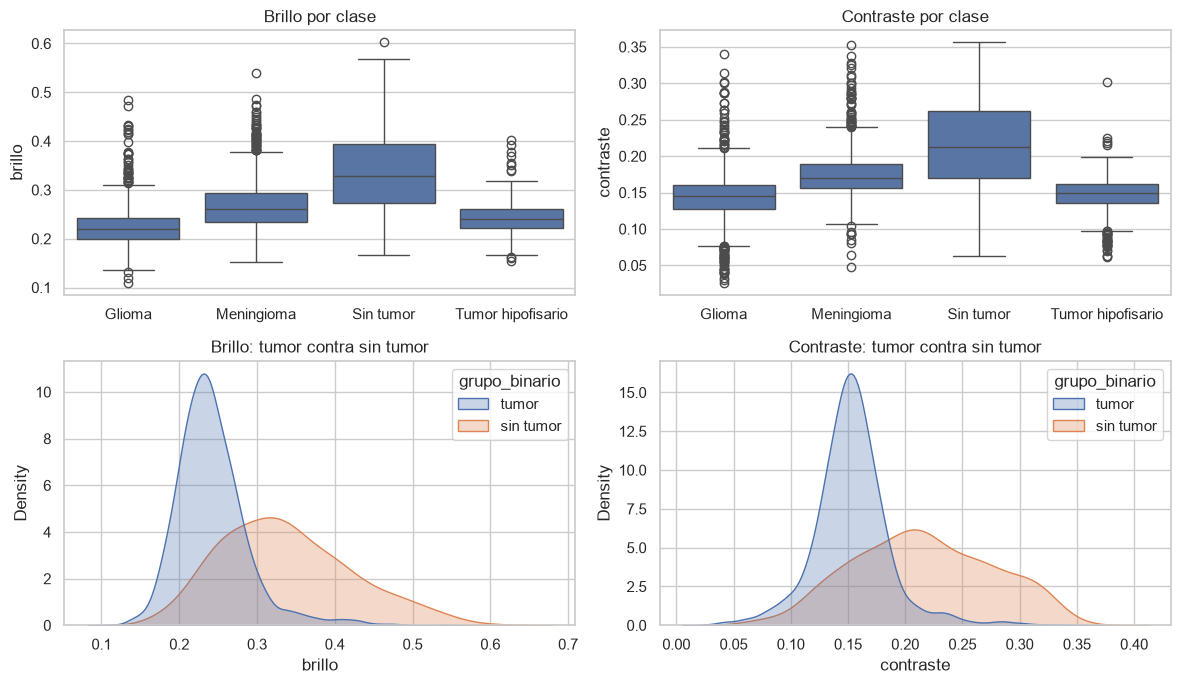

In [9]:
limpio["grupo_binario"] = np.where(limpio.es_tumor == 1, "tumor", "sin tumor")
limpio["nombre_clase"] = limpio.clase.map(config.NOMBRES_ES)
orden = [config.NOMBRES_ES[c] for c in config.CLASES]

descriptiva = limpio.groupby("clase")[["brillo", "contraste"]].agg(["count", "mean", "median", "std", "min", "max"]).round(4)
display(descriptiva)
display(limpio.groupby("grupo_binario")[["brillo", "contraste"]].agg(["count", "mean", "median", "std"]).round(4))

fig, axs = plt.subplots(2, 2, figsize=(12, 7))
sns.boxplot(data=limpio, x="nombre_clase", y="brillo", order=orden, ax=axs[0, 0]); axs[0, 0].set_title("Brillo por clase")
sns.boxplot(data=limpio, x="nombre_clase", y="contraste", order=orden, ax=axs[0, 1]); axs[0, 1].set_title("Contraste por clase")
sns.kdeplot(data=limpio, x="brillo", hue="grupo_binario", common_norm=False, fill=True, alpha=0.3, ax=axs[1, 0]); axs[1, 0].set_title("Brillo: tumor contra sin tumor")
sns.kdeplot(data=limpio, x="contraste", hue="grupo_binario", common_norm=False, fill=True, alpha=0.3, ax=axs[1, 1]); axs[1, 1].set_title("Contraste: tumor contra sin tumor")
for ax in axs[0]:
    ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_04_brillo_contraste.png", dpi=130); plt.show()

## 5. Intervalos de confianza
1. **Proporción de "sin tumor"** en los datos limpios, con el intervalo de Wilson al 95 %.
2. **Media del brillo** de cada grupo, con el intervalo t de Student al 95 %.

In [10]:
li, ls = wilson(n_sin, n)
print(f"Proporción de 'sin tumor': {n_sin / n:.4f} · IC 95 % de Wilson: [{li:.4f}, {ls:.4f}] (n = {n:,})")

filas_ic = []
for nombre, sub in limpio.groupby("grupo_binario"):
    for variable in ["brillo", "contraste"]:
        x = sub[variable].to_numpy()
        media, ee = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
        a, b = stats.t.interval(0.95, len(x) - 1, loc=media, scale=ee)
        filas_ic.append({"grupo": nombre, "variable": variable, "n": len(x), "media": media, "ic95_inferior": a, "ic95_superior": b})
tabla_ic = pd.DataFrame(filas_ic)
display(tabla_ic.round(4))

Proporción de 'sin tumor': 0.1019 · IC 95 % de Wilson: [0.0925, 0.1123] (n = 3,600)


,grupo,variable,n,media,ic95_inferior,ic95_superior
0,sin tumor,brillo,367,0.3375,0.3289,0.3461
1,sin tumor,contraste,367,0.2158,0.2096,0.2220
2,tumor,brillo,3233,0.2416,0.2400,0.2432
3,tumor,contraste,3233,0.1531,0.1520,0.1543


## 6. Pruebas de hipótesis
**Mann-Whitney U** (no supone normalidad), tumor contra sin tumor:
- H0: el brillo (o el contraste) tiene la misma distribución en los dos grupos.
- H1: las distribuciones son distintas. Nivel de significancia: 0.05.

Se reporta también el **tamaño del efecto** como la probabilidad de que una imagen con tumor sea más brillante que una sin tumor (0.5 = sin diferencia). Con miles de imágenes casi cualquier diferencia sale "significativa", así que el tamaño del efecto importa más que el valor p.

**Kruskal-Wallis** entre las 4 clases: H0 = la misma distribución en las cuatro.

In [11]:
filas_h = []
for variable in ["brillo", "contraste"]:
    a = limpio.loc[limpio.es_tumor == 1, variable].to_numpy()
    b = limpio.loc[limpio.es_tumor == 0, variable].to_numpy()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    filas_h.append({"prueba": "Mann-Whitney U (tumor contra sin tumor)", "variable": variable, "estadistico": u, "p_valor": p,
                    "efecto": u / (len(a) * len(b)), "detalle_efecto": "P(tumor > sin tumor)",
                    "mediana_tumor": np.median(a), "mediana_sin_tumor": np.median(b), "se_rechaza_H0": p < 0.05})
    grupos = [limpio.loc[limpio.clase == c, variable].to_numpy() for c in config.CLASES]
    h, pk = stats.kruskal(*grupos)
    filas_h.append({"prueba": "Kruskal-Wallis (4 clases)", "variable": variable, "estadistico": h, "p_valor": pk,
                    "efecto": (h - len(grupos) + 1) / (len(limpio) - len(grupos)), "detalle_efecto": "épsilon cuadrada",
                    "mediana_tumor": np.nan, "mediana_sin_tumor": np.nan, "se_rechaza_H0": pk < 0.05})
pruebas = pd.DataFrame(filas_h)
pruebas.to_csv(config.RESULTADOS / "eda_pruebas_hipotesis.csv", index=False, encoding="utf-8")
tabla_ic.to_csv(config.RESULTADOS / "eda_intervalos_confianza.csv", index=False, encoding="utf-8")
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
display(pruebas)
pd.reset_option("display.float_format")

for r in pruebas.itertuples():
    decision = "se rechaza H0" if r.se_rechaza_H0 else "no se rechaza H0"
    print(f"{r.prueba} · {r.variable}: estadístico = {r.estadistico:.4g}, p = {r.p_valor:.3g} → {decision}; {r.detalle_efecto} = {r.efecto:.3f}")

,prueba,variable,estadistico,p_valor,efecto,detalle_efecto,mediana_tumor,mediana_sin_tumor,se_rechaza_H0
0,Mann-Whitney U (tumor contra sin tumor),brillo,1.76e+05,2.447e-108,0.1484,P(tumor > sin tumor),0.2358,0.3291,True
1,Kruskal-Wallis (4 clases),brillo,1027,2.304e-222,0.2848,épsilon cuadrada,NaN,NaN,True
2,Mann-Whitney U (tumor contra sin tumor),contraste,2.221e+05,4.022e-86,0.1872,P(tumor > sin tumor),0.1521,0.2131,True
3,Kruskal-Wallis (4 clases),contraste,928.2,6.914e-201,0.2573,épsilon cuadrada,NaN,NaN,True


Mann-Whitney U (tumor contra sin tumor) · brillo: estadístico = 1.76e+05, p = 2.45e-108 → se rechaza H0; P(tumor > sin tumor) = 0.148
Kruskal-Wallis (4 clases) · brillo: estadístico = 1027, p = 2.3e-222 → se rechaza H0; épsilon cuadrada = 0.285
Mann-Whitney U (tumor contra sin tumor) · contraste: estadístico = 2.221e+05, p = 4.02e-86 → se rechaza H0; P(tumor > sin tumor) = 0.187
Kruskal-Wallis (4 clases) · contraste: estadístico = 928.2, p = 6.91e-201 → se rechaza H0; épsilon cuadrada = 0.257


### Interpretación y advertencia
La celda anterior imprime el resultado real de esta corrida. Cómo leerlo:
- Si **se rechaza H0**, el brillo o el contraste no se distribuyen igual en las imágenes con tumor y sin tumor. Eso **no** quiere decir que el brillo indique enfermedad: lo más probable es que refleje diferencias en cómo se obtuvieron las imágenes (equipo, tipo de corte, fuente de donde se juntó cada clase).
- **Advertencia:** un modelo podría apoyarse en el brillo general de la imagen y no en la anatomía. Por eso, en el notebook 03 se entrena a propósito un modelo que **solo** usa brillo, contraste e histograma: es la referencia mínima. Lo que ese modelo logre es lo que se puede "adivinar" sin mirar la forma del cerebro, y cualquier modelo mejor debe superarlo con claridad. El Grad-CAM del notebook 04 ayuda a revisar en qué zona se fija la red.
- Estos resultados describen **este dataset**; no se pueden generalizar a imágenes de otro hospital sin validarlo.

## 7. División en entrenamiento y prueba, por grupos
- **Prueba:** una de las 5 partes de `StratifiedGroupKFold(5, shuffle=True, random_state=42)`, estratificado por las **4 clases** y con los **grupos de similitud** como grupos: ningún grupo queda repartido. Es cerca de 20 %; no es exacto porque los grupos no se pueden partir.
- **Pliegues de la validación cruzada:** el entrenamiento se divide otra vez igual, en 5 pliegues por grupos. Se guardan en la columna `pliegue` del manifiesto para que **todos** los modelos usen exactamente los mismos.
- La prueba no se vuelve a tocar hasta la evaluación final de los notebooks 03 y 04.

particion,entrenamiento,prueba,total,porcentaje_en_prueba
clase,,,,
glioma,1166,291,1457,20.0
meningioma,655,164,819,20.0
notumor,294,73,367,19.9
pituitary,765,192,957,20.1
total,2880,720,3600,20.0


particion,entrenamiento,prueba
grupo_binario,,
sin tumor,10.21,10.14
tumor,89.79,89.86


Imágenes por pliegue y clase (entrenamiento):


clase,glioma,meningioma,notumor,pituitary,total
pliegue,,,,,
1,233,131,59,153,576
2,233,131,59,153,576
3,234,131,58,153,576
4,233,131,59,153,576
5,233,131,59,153,576
total,1166,655,294,765,2880


Valores de sha256 compartidos entre entrenamiento y prueba: 0
Valores de hash_perceptual compartidos entre entrenamiento y prueba: 0
Valores de sha256_preparada compartidos entre entrenamiento y prueba: 0
Valores de hash_perceptual_preparada compartidos entre entrenamiento y prueba: 0
Valores de grupo_similitud compartidos entre entrenamiento y prueba: 0


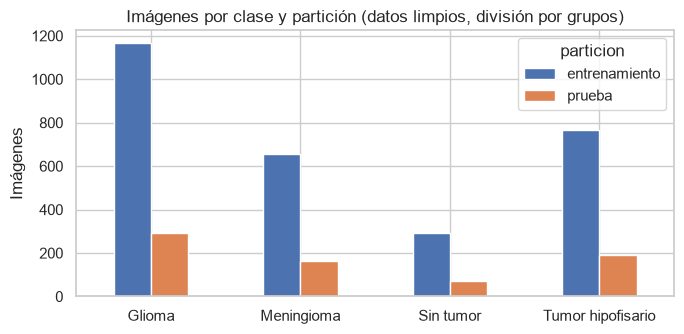

In [12]:
clases_limpio, grupos_limpio = limpio.clase.to_numpy(), limpio.grupo_similitud.to_numpy()
i_ent, i_pru = pliegues_estratificados(clases_limpio, 5, config.SEMILLA, grupos_limpio)[0]
limpio["particion"] = "entrenamiento"
limpio.loc[i_pru, "particion"] = "prueba"
limpio["pliegue"] = 0          # 0 = prueba; 1 a 5 = pliegue de la validación cruzada
pos_ent = np.flatnonzero((limpio.particion == "entrenamiento").to_numpy())
pos_pru = np.flatnonzero((limpio.particion == "prueba").to_numpy())
clases_ent, grupos_ent = clases_limpio[pos_ent], grupos_limpio[pos_ent]
PLIEGUES = pliegues_estratificados(clases_ent, config.N_PLIEGUES, config.SEMILLA, grupos_ent)
for k, (_, rel_pliegue) in enumerate(PLIEGUES, 1):
    limpio.loc[pos_ent[rel_pliegue], "pliegue"] = k

division = pd.crosstab(limpio.clase, limpio.particion, margins=True, margins_name="total").reindex(config.CLASES + ["total"])
division["porcentaje_en_prueba"] = (division.prueba / division.total * 100).round(1)
display(division)
display((pd.crosstab(limpio.grupo_binario, limpio.particion, normalize="columns") * 100).round(2))
print("Imágenes por pliegue y clase (entrenamiento):")
display(pd.crosstab(limpio.pliegue[limpio.pliegue > 0], limpio.clase, margins=True, margins_name="total"))

ent, pru = limpio[limpio.particion == "entrenamiento"], limpio[limpio.particion == "prueba"]
for h in HUELLAS + ["grupo_similitud"]:
    compartidos = set(ent[h]) & set(pru[h])
    print(f"Valores de {h} compartidos entre entrenamiento y prueba: {len(compartidos)}")
    assert not compartidos
assert ent.groupby("grupo_similitud").pliegue.nunique().max() == 1, "Un grupo quedó repartido entre pliegues."

ax = pd.crosstab(limpio.nombre_clase, limpio.particion).reindex(orden).plot(kind="bar", figsize=(7, 3.5), rot=0)
ax.set_xlabel(""); ax.set_ylabel("Imágenes"); ax.set_title("Imágenes por clase y partición (datos limpios, división por grupos)")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_05_division.png", dpi=130); plt.show()

### 7.1 Comprobación de fuga invariante a espejo y giro
Con los datos ya limpios y divididos se mide, para cada imagen, su mayor correlación de miniaturas (original y preparada, en las 8 orientaciones) con las imágenes **del otro lado** de cada frontera:
- **prueba ↔ entrenamiento**;
- **validación apartada ↔ su entrenamiento** (la parte que el notebook 04 aparta para la red, por grupos y con la misma semilla);
- **entre pliegues** de la validación cruzada (los 5 pliegues guardados en el manifiesto).

**Cómo leer la tabla**
- **Mayor de 0.98** (copias) y **mayor de 0.95** (la misma toma con otro contraste, copias recomprimidas, cortes casi idénticos): deben dar **0**. Las copias se eliminaron y lo que supera 0.95 viaja junto, en el mismo grupo.
- **Entre 0.90 y 0.95:** aquí **sí quedan parejas a los dos lados**, y no son solo "imágenes distintas". En esta banda hay sobre todo **cortes vecinos del mismo estudio** y también alguna toma repetida con un cambio de contraste o un recorte más fuerte. No se agrupan porque a ese nivel de parecido el encadenamiento ya une estudios enteros y tomas que no tienen relación.
- Los archivos `aug` (giros y zoom sintéticos) ya no están: se quitaron en el paso 1 porque su parecido con la imagen de origen cae por debajo de estos umbrales y no se podían controlar de otra forma.

**Límite que no se puede resolver con este dataset:** no trae identificador de paciente ni de estudio. Dos cortes distintos del mismo paciente pueden estar uno en entrenamiento y otro en prueba (**fuga por estudio**), así que las métricas de prueba siguen siendo, probablemente, algo optimistas respecto a pacientes nuevos.

In [13]:
MO, MP = MINI_O[POS_LIMPIO], MINI_P[POS_LIMPIO]


def gemelas(ia, ib):
    """Para cada imagen de `ia`: mayor correlación con alguna de `ib` (8 orientaciones, ambas miniaturas), cuál es y en qué orientación."""
    m1, k1, v1 = maxima_correlacion(MO[ia], MO[ib])
    m2, k2, v2 = maxima_correlacion(MP[ia], MP[ib])
    usa2 = m2 > m1
    return np.where(usa2, m2, m1), np.asarray(ib)[np.where(usa2, k2, k1)], np.where(usa2, v2, v1)


rel_tr, rel_va = apartar_validacion(clases_ent, 0.15, config.SEMILLA, grupos_ent)
print(f"Validación apartada del notebook 04 (por grupos): {len(rel_va)} imágenes; su entrenamiento: {len(rel_tr)}")
m_pru, par_pru, var_pru = gemelas(pos_pru, pos_ent)
maximos = {"prueba ↔ entrenamiento": m_pru,
           "validación apartada ↔ su entrenamiento": gemelas(pos_ent[rel_va], pos_ent[rel_tr])[0]}
entre_pliegues = np.zeros(len(pos_ent), dtype=np.float32)
for rel_resto, rel_pliegue in PLIEGUES:
    entre_pliegues[rel_pliegue] = gemelas(pos_ent[rel_pliegue], pos_ent[rel_resto])[0]
maximos["entre pliegues (cada imagen contra los otros 4 pliegues)"] = entre_pliegues

fuga = pd.DataFrame([{"frontera": nombre, "imagenes_revisadas": len(m),
                      "gemelas_corr_mayor_098": int((m > 0.98).sum()), "gemelas_corr_mayor_095": int((m > 0.95).sum()),
                      "gemelas_banda_090_095": int(((m > 0.90) & (m <= 0.95)).sum()),
                      "gemelas_corr_mayor_090": int((m > 0.90).sum()),
                      "porcentaje_mayor_090": round(float((m > 0.90).mean() * 100), 2), "correlacion_maxima": float(m.max())}
                     for nombre, m in maximos.items()])
fuga.to_csv(config.RESULTADOS / "eda_fuga_gemelas.csv", index=False, encoding="utf-8")
display(fuga)
for r in fuga.itertuples():
    print(f"{r.frontera}: de {r.imagenes_revisadas:,} imágenes, {r.gemelas_corr_mayor_098} tienen al otro lado una gemela con correlación > 0.98, "
          f"{r.gemelas_corr_mayor_095} con > 0.95 y {r.gemelas_banda_090_095} en la banda 0.90–0.95 ({r.porcentaje_mayor_090} % con > 0.90)")
sin_tumor_pru = limpio.es_tumor.to_numpy()[pos_pru] == 0
print(f"Prueba 'sin tumor': {int(sin_tumor_pru.sum())} imágenes · con gemela > 0.95 en entrenamiento: {int((m_pru[sin_tumor_pru] > 0.95).sum())} "
      f"· en la banda 0.90–0.95: {int(((m_pru[sin_tumor_pru] > 0.90) & (m_pru[sin_tumor_pru] <= 0.95)).sum())}")
assert int(fuga.gemelas_corr_mayor_095.sum()) == 0, "Quedaron gemelas (correlación > 0.95) entre particiones."

Validación apartada del notebook 04 (por grupos): 412 imágenes; su entrenamiento: 2468


,frontera,imagenes_revisadas,gemelas_corr_mayor_098,gemelas_corr_mayor_095,gemelas_banda_090_095,gemelas_corr_mayor_090,porcentaje_mayor_090,correlacion_maxima
0,prueba ↔ entrenamiento,720,0,0,318,318,44.17,0.949782
1,validación apartada ↔ su entrenamiento,412,0,0,169,169,41.02,0.949832
2,entre pliegues (cada imagen contra los otros 4...,2880,0,0,1057,1057,36.70,0.949832


prueba ↔ entrenamiento: de 720 imágenes, 0 tienen al otro lado una gemela con correlación > 0.98, 0 con > 0.95 y 318 en la banda 0.90–0.95 (44.17 % con > 0.90)
validación apartada ↔ su entrenamiento: de 412 imágenes, 0 tienen al otro lado una gemela con correlación > 0.98, 0 con > 0.95 y 169 en la banda 0.90–0.95 (41.02 % con > 0.90)
entre pliegues (cada imagen contra los otros 4 pliegues): de 2,880 imágenes, 0 tienen al otro lado una gemela con correlación > 0.98, 0 con > 0.95 y 1057 en la banda 0.90–0.95 (36.7 % con > 0.90)
Prueba 'sin tumor': 73 imágenes · con gemela > 0.95 en entrenamiento: 0 · en la banda 0.90–0.95: 6


Los 5 pares prueba ↔ entrenamiento de **mayor correlación que quedan** (todos por debajo de 0.95). Sirven para juzgar a simple vista qué tan parecidas son las imágenes que la división todavía separa.

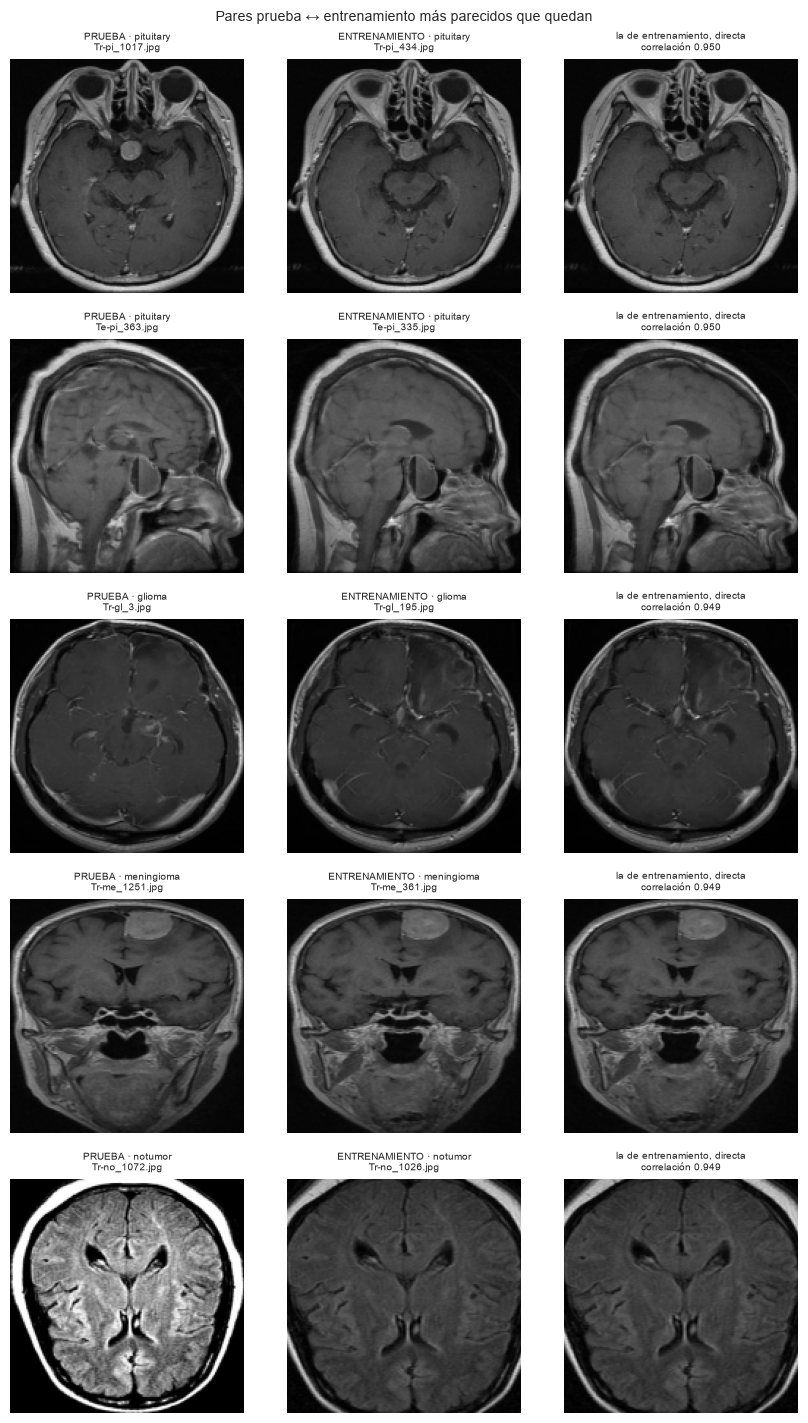

In [14]:
top = np.argsort(-m_pru)[:5]
fig, axs = plt.subplots(len(top), 3, figsize=(8.5, 2.9 * len(top)), squeeze=False)
for fila, k in zip(axs, top):
    a, b = limpio.iloc[pos_pru[k]], limpio.iloc[par_pru[k]]
    img_b = preparar(leer_imagen(config.RAIZ / b.ruta))
    fila[0].imshow(preparar(leer_imagen(config.RAIZ / a.ruta))); fila[0].set_title(f"PRUEBA · {a.clase}\n{Path(a.ruta).name}", fontsize=7)
    fila[1].imshow(img_b); fila[1].set_title(f"ENTRENAMIENTO · {b.clase}\n{Path(b.ruta).name}", fontsize=7)
    fila[2].imshow(VOLTEAR[var_pru[k]](img_b)); fila[2].set_title(f"la de entrenamiento, {var_pru[k].replace('_', ' ')}\ncorrelación {m_pru[k]:.3f}", fontsize=7)
    for ax in fila:
        ax.axis("off")
fig.suptitle("Pares prueba ↔ entrenamiento más parecidos que quedan", fontsize=10)
plt.tight_layout(); plt.savefig(FIGURAS / "eda_06_pares_prueba_entrenamiento.png", dpi=120); plt.show()

## 8. Desbalance
En el problema binario hay muchas más imágenes con tumor que sin tumor, y al quitar duplicados el desbalance crece, porque la clase "sin tumor" es la que más copias tenía (las cifras exactas están en la sección 3.1 y en la celda de abajo). Un modelo que dijera siempre "tumor" tendría una exactitud alta y no serviría: por eso la exactitud no es la métrica principal.

**Cómo se trata:** con **pesos de clase** (`class_weight="balanced"` en scikit-learn y una pérdida ponderada en Keras). No se duplican ni se eliminan imágenes. Los pesos se calculan solo con el entrenamiento.

**Métrica principal:** la **sensibilidad**, porque el error más costoso es el falso negativo (un tumor que se pasa por alto). El umbral de decisión se elige para una sensibilidad objetivo de 0.98 en validación, y se reportan también especificidad, precisión, F1 y AUC.

In [15]:
pesos = pesos_clase(ent.es_tumor)
print(f"Entrenamiento: {int((ent.es_tumor == 1).sum()):,} con tumor y {int((ent.es_tumor == 0).sum()):,} sin tumor")
print(f"Pesos de clase balanceados → sin tumor: {pesos[0]:.4f} · tumor: {pesos[1]:.4f}")

Entrenamiento: 2,586 con tumor y 294 sin tumor
Pesos de clase balanceados → sin tumor: 4.8980 · tumor: 0.5568


## 9. Manifiesto
`datos/manifiesto.csv` es la única lista de imágenes que usan los demás notebooks y la aplicación.

In [16]:
limpio["grupo"] = limpio.grupo_similitud   # mismo valor; se conserva el nombre anterior de la columna
columnas = ["ruta", "carpeta_origen", "clase", "es_tumor", "sha256", "hash_perceptual", "particion", "pliegue", "grupo_similitud", "grupo",
            "sha256_preparada", "hash_perceptual_preparada",
            "ancho", "alto", "brillo", "contraste"]
manifiesto = limpio[columnas]
manifiesto.to_csv(config.MANIFIESTO, index=False, encoding="utf-8")
print("Guardado:", config.MANIFIESTO, f"({len(manifiesto):,} filas)")
display(manifiesto.head())

resumen = pd.Series({
    "imagenes_en_carpetas": len(filas), "ilegibles": n_ilegibles, "demasiado_pequenas": n_chicas,
    "quitadas_por_aumento_del_dataset": int((df.causa == CAUSA_AUG).sum()),
    "quitadas_por_etiqueta_contradictoria": int((df.causa == CAUSA_CONTRA).sum()),
    "pares_contradictorios": len(choque),
    "quitadas_por_copia_exacta": int((df.causa == CAUSA_EXACTA).sum()),
    "quitadas_por_casi_identica": int((df.causa == CAUSA_CASI).sum()),
    "quitadas_por_espejo_o_giro": int((df.causa == CAUSA_ESPEJO).sum()),
    "quitadas_total": int((df.accion == "quitada").sum()),
    "recuperadas_frente_al_metodo_encadenado": int(recuperadas.loc["total", "recuperadas"]),
    "imagenes_limpias": len(limpio),
    "grupos_de_similitud": int(limpio.grupo_similitud.nunique()),
    "grupo_de_similitud_mas_grande": int(resumen_grupos["grupo más grande (imágenes)"]),
    "entrenamiento": len(ent), "prueba": len(pru),
}, name="valor")
resumen.to_csv(config.RESULTADOS / "eda_resumen.csv", header=True, index_label="concepto", encoding="utf-8")
display(resumen.to_frame())
print(f"Notebook terminado en {time.time() - INICIO:.0f} s")

Guardado: C:\proyectos\tumores-cerebrales\datos\manifiesto.csv (3,600 filas)


,ruta,carpeta_origen,clase,es_tumor,sha256,hash_perceptual,particion,pliegue,grupo_similitud,grupo,sha256_preparada,hash_perceptual_preparada,ancho,alto,brillo,contraste
0,datos/Training/glioma/Tr-gl_1.jpg,Training,glioma,1,eb139c78b32d818c5bba63983ceeaa560b71b7e427251a...,000003c00ff01ff83ff83ff83ffc3ffc3ffc3fc837e83f...,entrenamiento,1,0,0,0766481464780ec89283219f0c4fbd2ba875d6c908d875...,7ff8c03803dc7ffefffe7ffe1ffe0ffe1fc608c03de4ff...,512,512,0.207823,0.113185
1,datos/Training/glioma/Tr-gl_10.jpg,Training,glioma,1,7441c7ea5c1474ae20efdc2169e7e86d81204289354d86...,03000fe01ff03ff83ffc3ffc3ffc3ffc3ffc3fdc3ffc3f...,entrenamiento,2,1,1,4f5f4d2d4fe3281608df7bbf0488a376504e05b1fd1e4f...,0fc01c703fdc7f9c7ffefffffffdfff9ffef4fce7fee7b...,512,512,0.240194,0.163783
2,datos/Training/glioma/Tr-gl_100.jpg,Training,glioma,1,db7bc5885e0f6f532fa2757dc3aa5a23db57eeb1c58189...,0000000003800fe01ff03ff83ff83ff83ffc3ff03ff83f...,prueba,0,2,2,f4edf13578677e208dd1b4ee12cd70eb06503080b1d7d6...,0fe0383827ec5ff2fffcbffcbfe5bfdd9ddcdd9646e37f...,512,512,0.268639,0.163834
3,datos/Training/glioma/Tr-gl_1000.jpg,Training,glioma,1,e7310f1c588b7b5259754665a81e2aacf78cc97b10d801...,02000fc01ff03ff82ffc7ffe7ffe7ffe7ffa3fc63fcc3f...,entrenamiento,3,3,3,82c36afd8b067bd99a3a00c8a152848bd79ce02d6046b6...,e7cccf061ff33ffc7ffe7fdf7fef7eff7fe83fc0bf80bb...,512,512,0.223719,0.114447
4,datos/Training/glioma/Tr-gl_1001.jpg,Training,glioma,1,d7595c5cf5e8747271e162b0ef4399c38f8d97c16c371c...,0000000007e00ff00ff01ff81ff81ff81ff81ff81ff80f...,entrenamiento,5,4,4,e204f77505bb57a0e7eef687d934f9ee00cf78f3ca08ba...,07e0189017e81ff05ffe5ffffdfdbdfdb9e1b9fd9fff4f...,512,512,0.229865,0.158315


,valor
imagenes_en_carpetas,7200
ilegibles,0
demasiado_pequenas,0
quitadas_por_aumento_del_dataset,203
quitadas_por_etiqueta_contradictoria,34
pares_contradictorios,27
quitadas_por_copia_exacta,215
quitadas_por_casi_identica,409
quitadas_por_espejo_o_giro,2739
quitadas_total,3600


Notebook terminado en 162 s
